# Step back

**이 노트북에서 할 일**

1. Ch 12에서 쓰던 문서 열두 건과 질문 여덟 개를 그대로 읽습니다.
2. 한 사례의 세부가 담긴 구체 질문을 하나 정합니다.
3. 그 질문을 한 번만 검색해 정답 문서의 자리를 셉니다.
4. 같은 질문을 한 단계 넓힌 질문으로 바꿔 다시 검색합니다.
5. 두 검색의 첫 자리 문서를 모아 근거 문서 목록을 만듭니다.
6. 질문만 바꾸어 같은 일을 다시 하고 두 결과를 견줍니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
서비스 요청은 일곱 번입니다(임베딩 다섯 번과 답 모델 두 번).
예상 비용은 미화 0.01달러 아래입니다.
읽어 오는 파일은 이 챕터 폴더의 문서 파일과 질문 파일 둘이고 새로 쓰는 파일은 없습니다.
실행 시간은 2분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3과 도구 파일이 쓰는 numpy 2.5.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3절부터 7절까지 읽습니다.
Ch 12 검색 부품을 준비하고 한 사례의 세부가 담긴 질문을 고르는 자리입니다.
8절과 9절은 넓힌 질문을 만들어 다시 검색하는 자리입니다.
10절과 11절은 질문을 바꾸어 같은 일을 한 번 더 하고 네 실행을 표로 보는 자리입니다.

실습 폴더 `labs/part4/ch14-rag-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

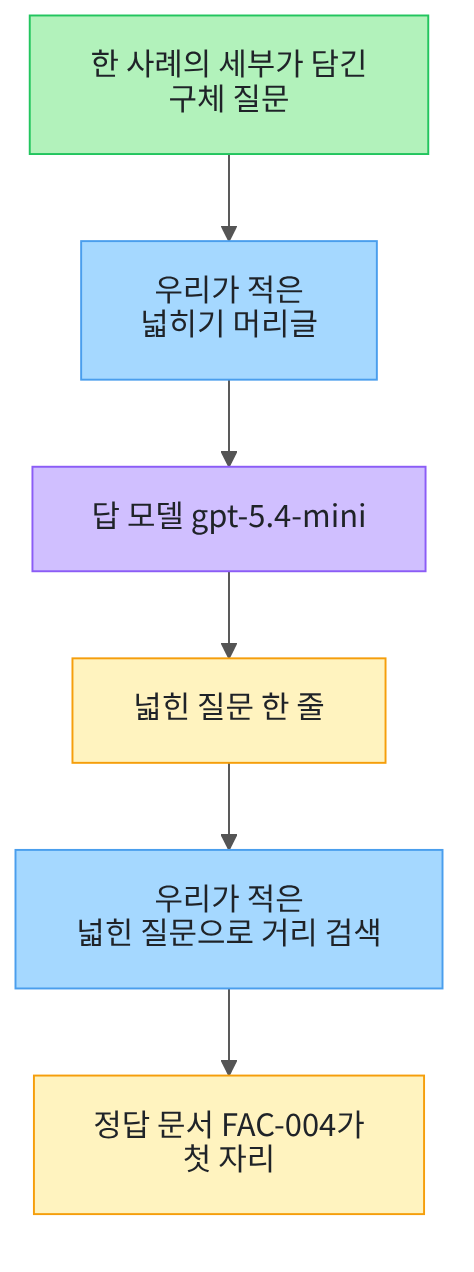

위에서 아래로 읽습니다.
맨 위 초록 상자가 사람이 적은 질문입니다.
가운데 파란 상자 둘이 우리가 적은 글과 처리이고 보라 상자가 모델입니다.
노란 상자 둘이 출력으로 확인한 값입니다.

## 1. 준비

첫 셀은 패키지 네 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3" "numpy==2.5.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 판 번호 네 줄이 보입니다.
마지막 줄 `numpy: 2.5.3`은 도구 파일이 벡터 계산에 쓰는 패키지입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이름 네 개를 불러오고 도구 파일에서 함수 일곱 개를 가져옵니다.
앞의 둘은 자료 읽기와 폴더 확인에 씁니다.
뒤의 둘은 Ch 9~13에서 쓴 임베딩과 답 모델 이름입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 Ch 12 01절 `rank_by_distance()`와 05절 `print_ranked()`를 가져옵니다.
Ch 11 01절 `unique_doc_ids()`·`find_gold_rank()`와 01절 `run_row()`도 가져옵니다.
02절에서 만든 `split_lines()`와 `search_ids()`도 함께 가져옵니다.
인자 모양은 5절에서 설명합니다.

In [2]:
# 자료 읽기·폴더 확인과 임베딩·답 모델 이름을 불러옵니다
import json
import os

from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model
# Ch 12 01·05절·Ch 11 01절 함수와 01·02절 함수를 도구 파일에서 가져옵니다
from rag_tools import find_gold_rank, print_ranked, rank_by_distance, run_row
from rag_tools import search_ids, split_lines, unique_doc_ids

print("불러온 이름:", "json", "os", "OpenAIEmbeddings", "init_chat_model")

불러온 이름: json os OpenAIEmbeddings init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 네 개가 보입니다.
이름 `OpenAIEmbeddings`와 `init_chat_model`은 03절에서 쓴 것과 같습니다.
도구 파일에서 가져온 함수 일곱 개는 출력하지 않습니다.

## 2. 키와 모델 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 문서와 질문 읽기

이 절은 01~03절과 같은 문서 파일과 질문 파일을 읽습니다.
두 파일은 Ch 12 core 벌 파일과 바이트가 같은 사본입니다.
먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리` 뒤에 점 하나나 위로 올라가는 표시가 보입니다.
Ch 10~13과 01~03절에서 쓴 방법과 같습니다.
후보 셋 가운데 이 챕터 자료 폴더가 있는 자리를 고릅니다.

다음 셀은 문서 파일과 질문 파일을 읽습니다.

In [6]:
# 이 챕터 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`이 Ch 12 core 벌 그대로입니다.
문서는 도서관 안내 열두 건입니다.

질문 번호는 C01부터 C08까지이고 질문 파일에 적혀 있습니다.
이 절이 쓸 질문은 그 여덟 개에 없어 아래에서 손으로 적습니다.

## 4. 이 절에서 쓸 값 정하기

Ch 12와 01~03절에서 정한 값을 그대로 다시 적습니다.
만들 넓힌 질문 개수도 여기서 못 박아 둡니다.

In [7]:
# Ch 12에서 쓴 값을 그대로 다시 정하고 만들 넓힌 질문 개수도 못 박습니다
top_three = 3
top_all = 12
broad_count = 1
print("나란히 볼 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)
print("만들 넓힌 질문 수:", broad_count)

나란히 볼 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12
만들 넓힌 질문 수: 1


**결과 읽기** — 출력 줄 `나란히 볼 상위 문서 수: 3`은 표로 볼 자리 수입니다.
출력 줄 `자리를 셀 때 재는 문서 수: 12`는 정답 문서의 자리를 끝까지 세려고 둔 값입니다.
출력 줄 `만들 넓힌 질문 수: 1`은 이 절이 만들 넓힌 질문 개수입니다.

03절은 이 자리에 하위 질문 개수 둘을 두었습니다.
이 절은 한 줄만 받으므로 값이 하나입니다.

## 5. 앞 절 부품 준비

다음 셀은 01~03절과 같은 방법으로 문서 열두 건의 제목과 본문을 이어 붙입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.
함수는 준비 셀에서 도구 파일로 가져왔습니다.
02절 `search_ids()`의 도구 파일 판은 임베딩 모델과 질문과 문서 벡터 목록과 문서 ID 목록과 개수를 받습니다.

In [8]:
# 문서 12개의 제목과 본문을 이어 붙이고 문서 ID 목록도 만듭니다(Ch 12와 같은 제목 + 본문 모양)
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
print("이어 붙인 글 수:", len(doc_texts))
print("첫 문서 글:", doc_texts[0])
print("문서 ID 목록:")
print(doc_ids)

이어 붙인 글 수: 12
첫 문서 글: 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


준비 셀 하나를 지났습니다.
02·03절이 쓴 순위 합치기 함수는 이 절에서 가져오지 않았습니다.
이 절은 목록 여러 개를 하나로 합치지 않기 때문입니다.

## 6. 문서를 벡터로 바꾸기

다음 셀은 문서 열두 건을 벡터로 바꿉니다.
이 절에서 서비스에 보내는 첫 요청입니다.

In [9]:
# Ch 12와 같은 모델로 문서 12개를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 03절과 같은 모델입니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~13과 같은 값입니다.
출력 줄 `문서 벡터 수: 12`로 문서마다 벡터 하나를 받았습니다.
벡터 안의 숫자는 호출마다 아주 조금씩 달라져 소수 자리까지 같다고 보지 않습니다.

## 7. 한 사례의 세부가 담긴 질문

자료의 여덟 질문은 저마다 규칙을 바로 묻습니다.
사람이 겪은 일을 그대로 옮긴 질문은 그와 다릅니다.
날짜와 물건 이름 같은 세부가 함께 들어갑니다.
그런 질문을 하나 적고 판단에 쓸 정답 문서도 함께 정합니다.

In [10]:
# 한 사례의 세부가 담긴 구체 질문과 그 질문의 정답 문서를 정합니다
base_question = "지난달에 도서관에서 우산을 잃어버렸는데 지금도 찾을 수 있나요?"
gold_doc_id = "FAC-004"
gold_title = ""
for doc in docs:
    if doc["doc_id"] == gold_doc_id:
        gold_title = doc["title"]
print("구체 질문:", base_question)
print("이 질문의 정답 문서 ID:", gold_doc_id)
print("그 문서의 제목:", gold_title)

구체 질문: 지난달에 도서관에서 우산을 잃어버렸는데 지금도 찾을 수 있나요?
이 질문의 정답 문서 ID: FAC-004
그 문서의 제목: 분실물 보관


**결과 읽기** — 출력 줄 `구체 질문` 뒤에 지난달과 우산이 들어간 물음이 있습니다.
출력 줄 `이 질문의 정답 문서 ID: FAC-004`는 보관 기간을 적은 문서입니다.
출력 줄 `그 문서의 제목: 분실물 보관`으로 제목을 확인했습니다.

실행 전에 예상해 봅니다.
질문에 든 말이 그 문서에 거의 없으니 다른 문서가 먼저 걸릴 것입니다.

In [11]:
# 구체 질문을 한 번만 검색해 순위 표와 정답 문서의 자리를 봅니다(임베딩 요청 1번)
base_vector = embedding_model.embed_query(base_question)
base_hits = rank_by_distance(base_vector, doc_vectors, doc_ids, top_all)
base_ids = unique_doc_ids(base_hits)
base_place = find_gold_rank(base_ids, [gold_doc_id])
print_ranked(base_hits[:top_three], "거리")
print("구체 질문으로 한 번 검색했을 때 정답 문서의 자리:", base_place)

순위 | 문서 ID | 거리
1 | LIB-003 | 0.63
2 | FAC-003 | 0.67
3 | ACC-004 | 0.68
구체 질문으로 한 번 검색했을 때 정답 문서의 자리: 8


**결과 읽기** — 순위 표의 차례는 `LIB-003`과 `FAC-003`과 `ACC-004`입니다.
세 문서 모두 이 물음의 정답 문서가 아닙니다.
출력 줄 `구체 질문으로 한 번 검색했을 때 정답 문서의 자리: 8`로 정답 문서는 여덟째였습니다.

거리 값은 셋째 자리 아래가 호출마다 달라져 본문과 그림에 넣지 않았습니다.
질문에 든 날짜와 물건 이름이 자료의 규칙 문장에는 없습니다.

## 8. 한 단계 넓힌 질문 만들기

이번에는 질문을 잘게 나누지 않습니다.
사례의 세부를 빼고 판단에 필요한 규칙만 묻도록 한 줄을 받습니다.
머리글에 개수와 모양을 적고 없는 조건을 새로 넣지 말라는 줄도 함께 넣습니다.

In [12]:
# 머리글 네 줄과 원 질문을 한 글로 이어 붙입니다
def build_back_prompt(question):
    back_head = "아래 질문은 한 사례의 세부 상황을 담고 있습니다.\n"
    back_head = back_head + "판단에 필요한 일반 규칙을 찾을 검색 질문을 " + str(broad_count) + "줄 적으세요.\n"
    back_head = back_head + "한 줄만 적고 번호나 따옴표를 붙이지 마세요.\n"
    back_head = back_head + "원 질문에 없는 조건을 새로 넣지 마세요.\n\n"
    prompt_text = back_head + "질문: " + question
    return prompt_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_back_prompt`는 머리글 네 줄을 이어 붙인 뒤 원 질문을 답니다.
머리글의 개수 자리에는 앞에서 정한 값 `broad_count`가 들어갑니다.
03절 머리글과 다른 줄은 첫 줄과 셋째 줄입니다.

다음 셀은 그 글을 만들어 모델에 넣습니다.

In [13]:
# 만든 글을 모델에 넣어 한 단계 넓힌 질문을 받습니다(모델 요청 1번)
back_prompt = build_back_prompt(base_question)
print("모델에 넣을 글:")
print(back_prompt)
back_reply = model.invoke(back_prompt)
back_text = back_reply.text.strip()
print("모델이 쓴 글:")
print(back_text)

모델에 넣을 글:
아래 질문은 한 사례의 세부 상황을 담고 있습니다.
판단에 필요한 일반 규칙을 찾을 검색 질문을 1줄 적으세요.
한 줄만 적고 번호나 따옴표를 붙이지 마세요.
원 질문에 없는 조건을 새로 넣지 마세요.

질문: 지난달에 도서관에서 우산을 잃어버렸는데 지금도 찾을 수 있나요?


모델이 쓴 글:
도서관에서 분실한 물건을 시간이 지난 뒤에도 찾을 수 있는지와 분실물 문의 절차는 어떻게 되나요


**결과 읽기** — 라벨 줄 `모델에 넣을 글:` 아래에 머리글 네 줄과 원 질문이 있습니다.
라벨 줄 `모델이 쓴 글:` 아래에는 질문 한 줄이 있습니다.
그 줄에는 지난달도 우산도 없습니다.
문장은 실행마다 달라질 수 있어 이 값에 `assert`를 걸지 않았습니다.

03절 하위 질문은 원 질문보다 좁았습니다.
이 절 넓힌 질문은 원 질문보다 넓습니다.

## 9. 넓힌 질문으로 검색하기

모델이 보낸 글에서 맨 앞 한 줄만 씁니다.
02절에서 만든 함수로 빈 줄을 빼고 줄 목록을 만듭니다.

In [14]:
# 모델이 보낸 글을 줄로 나누고 맨 앞 한 줄만 넓힌 질문으로 씁니다
back_lines = split_lines(back_text)
broad_question = back_lines[0]
print("모델이 보낸 줄 수:", len(back_lines))
print("쓸 넓힌 질문 수:", broad_count)
print("넓힌 질문:", broad_question)

모델이 보낸 줄 수: 1
쓸 넓힌 질문 수: 1
넓힌 질문: 도서관에서 분실한 물건을 시간이 지난 뒤에도 찾을 수 있는지와 분실물 문의 절차는 어떻게 되나요


**결과 읽기** — 출력 줄 `쓸 넓힌 질문 수: 1`은 앞에서 정한 개수와 같습니다.
출력 줄 `넓힌 질문` 뒤에 실제로 검색에 넣을 한 줄이 있습니다.
받은 줄이 더 많아도 맨 앞 한 줄만 씁니다.

다음 셀은 그 한 줄로 다시 검색합니다.

In [15]:
# 넓힌 질문으로 다시 검색해 순위 표와 정답 문서의 자리를 봅니다(임베딩 요청 1번)
broad_vector = embedding_model.embed_query(broad_question)
broad_hits = rank_by_distance(broad_vector, doc_vectors, doc_ids, top_all)
broad_ids = unique_doc_ids(broad_hits)
broad_place = find_gold_rank(broad_ids, [gold_doc_id])
print_ranked(broad_hits[:top_three], "거리")
print("넓힌 질문으로 검색했을 때 정답 문서의 자리:", broad_place)

순위 | 문서 ID | 거리
1 | FAC-004 | 0.54
2 | LIB-002 | 0.63
3 | FAC-003 | 0.68
넓힌 질문으로 검색했을 때 정답 문서의 자리: 1


**결과 읽기** — 순위 표의 첫 자리는 `FAC-004`입니다.
출력 줄 `넓힌 질문으로 검색했을 때 정답 문서의 자리: 1`로 정답 문서가 맨 앞에 왔습니다.
같은 문서가 구체 질문에서는 여덟째 자리였습니다.

넓힌 질문에는 사례의 세부가 없고 규칙을 묻는 말만 있습니다.
그래서 규칙을 적은 문서와 가까워졌습니다.
순위 표의 둘째 줄과 셋째 줄은 새 커널로 다시 실행하면 달라집니다.
모델이 쓴 문장이 바뀌면 그 아래 차례도 함께 바뀌기 때문입니다.

In [16]:
# 두 검색의 첫 자리 문서를 모으고 겹치는 문서를 빼 근거 문서 목록을 만듭니다
top_hits = []
top_hits.append({"doc_id": base_ids[0]})
top_hits.append({"doc_id": broad_ids[0]})
evidence_ids = unique_doc_ids(top_hits)
print("구체 질문 첫 자리 문서:", base_ids[0])
print("넓힌 질문 첫 자리 문서:", broad_ids[0])
print("근거 문서 목록:", evidence_ids)

구체 질문 첫 자리 문서: LIB-003
넓힌 질문 첫 자리 문서: FAC-004
근거 문서 목록: ['LIB-003', 'FAC-004']


**결과 읽기** — 출력 줄 `근거 문서 목록: ['LIB-003', 'FAC-004']`가 이 절이 얻으려던 값입니다.
앞의 문서는 구체 질문이 찾은 문서이고 정답 문서가 아닙니다.
뒤의 문서는 넓힌 질문이 찾은 정답 문서입니다.

원 질문 목록을 지우지 않는 까닭이 여기 있습니다.
세부 조건을 적은 문서가 따로 있는 자료에서는 그 문서를 놓치지 않아야 합니다.

## 10. 값 바꿔 보기 · 이미 규칙을 묻는 질문

바꿀 값은 검색에 쓸 질문 하나입니다.
머리글도 넓힐 개수도 그대로 두고 질문만 바꿉니다.
정답 문서도 앞과 같은 문서로 둡니다.
실행 전에 예상해 봅니다.
이미 규칙을 바로 묻는 질문이라 넓혀도 자리가 그대로일 것입니다.

In [17]:
# 바꿀 값은 검색에 쓸 질문 하나이고 이번에는 규칙을 바로 묻는 질문입니다(임베딩 요청 1번)
second_question = "분실물은 얼마 동안 보관하나요?"
second_ids = search_ids(embedding_model, second_question, doc_vectors, doc_ids, top_all)
second_place = find_gold_rank(second_ids, [gold_doc_id])
print("바꾼 질문:", second_question)
print("정답 문서는 앞과 같은 ID:", gold_doc_id)
print("바꾼 질문으로 한 번 검색했을 때 정답 문서의 자리:", second_place)

바꾼 질문: 분실물은 얼마 동안 보관하나요?
정답 문서는 앞과 같은 ID: FAC-004
바꾼 질문으로 한 번 검색했을 때 정답 문서의 자리: 1


**결과 읽기** — 출력 줄 `바꾼 질문` 뒤에 보관 기간을 바로 묻는 한 줄이 있습니다.
출력 줄 `정답 문서는 앞과 같은 ID: FAC-004`로 좇는 문서는 그대로입니다.
출력 줄 `바꾼 질문으로 한 번 검색했을 때 정답 문서의 자리: 1`로 첫 자리였습니다.

다음 셀은 같은 머리글로 이 질문도 한 단계 넓힙니다.

In [18]:
# 같은 머리글로 바꾼 질문도 한 단계 넓혀 봅니다(모델 요청 1번)
second_prompt = build_back_prompt(second_question)
second_reply = model.invoke(second_prompt)
second_text = second_reply.text.strip()
second_lines = split_lines(second_text)
second_broad = second_lines[0]
print("모델이 보낸 줄 수:", len(second_lines))
print("넓힌 질문:", second_broad)

모델이 보낸 줄 수: 1
넓힌 질문: 분실물 보관 기간은 법령이나 기관별 규정에 따라 얼마나 되나요?


**결과 읽기** — 라벨 줄 `넓힌 질문:` 아래에 모델이 쓴 한 줄이 있습니다.
이번 질문에는 뺄 세부가 거의 없어 원 질문과 묻는 것이 비슷합니다.
문장은 실행마다 달라질 수 있습니다.

다음 셀은 그 한 줄로 같은 방법으로 검색합니다.

In [19]:
# 바꾼 질문의 넓힌 질문으로 검색해 같은 방법으로 근거 문서 목록을 만듭니다(임베딩 요청 1번)
second_broad_ids = search_ids(embedding_model, second_broad, doc_vectors, doc_ids, top_all)
second_broad_place = find_gold_rank(second_broad_ids, [gold_doc_id])
second_hits = []
second_hits.append({"doc_id": second_ids[0]})
second_hits.append({"doc_id": second_broad_ids[0]})
second_evidence = unique_doc_ids(second_hits)
print("넓힌 질문으로 검색했을 때 정답 문서의 자리:", second_broad_place)
print("근거 문서 목록:", second_evidence)

넓힌 질문으로 검색했을 때 정답 문서의 자리: 1
근거 문서 목록: ['FAC-004']


**결과 읽기** — 출력 줄 `넓힌 질문으로 검색했을 때 정답 문서의 자리: 1`로 자리가 그대로입니다.
출력 줄 `근거 문서 목록: ['FAC-004']`로 근거 문서가 하나입니다.
두 검색이 같은 문서를 첫 자리에 두어 목록에 하나만 남았습니다.
넓히기가 늘 자리를 올리지는 않습니다.

## 11. 네 실행을 기록 한 줄씩으로

실행 하나를 기록 한 줄로 만들어 담아 둡니다.
기록 한 줄은 준비 셀에서 도구 파일로 가져온 01절 `run_row()`로 만듭니다.
담는 칸은 실행 이름과 검색에 쓴 질문과 첫 자리 문서와 정답 자리 넷입니다.
03절만 근거가 둘이라 자리를 둘 담았고 이 절은 좇는 문서가 하나라 01·02절 판을 씁니다.

다음 셀은 네 실행의 기록을 표로 출력합니다.

In [20]:
# 네 실행의 기록을 담아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("구체 질문 한 번 검색", base_question, base_ids, base_place))
run_rows.append(run_row("넓힌 질문 검색", broad_question, broad_ids, broad_place))
run_rows.append(run_row("바꾼 질문 한 번 검색", second_question, second_ids, second_place))
run_rows.append(run_row("바꾼 질문의 넓힌 질문", second_broad, second_broad_ids, second_broad_place))
print("실행 | 검색에 쓴 질문 | 첫 자리 문서 | 정답 자리")
for row in run_rows:
    print(row["실행"], "|", row["검색에 쓴 질문"], "|", row["첫 자리 문서"], "|", row["정답 자리"])

실행 | 검색에 쓴 질문 | 첫 자리 문서 | 정답 자리
구체 질문 한 번 검색 | 지난달에 도서관에서 우산을 잃어버렸는데 지금도 찾을 수 있나요? | LIB-003 | 8
넓힌 질문 검색 | 도서관에서 분실한 물건을 시간이 지난 뒤에도 찾을 수 있는지와 분실물 문의 절차는 어떻게 되나요 | FAC-004 | 1
바꾼 질문 한 번 검색 | 분실물은 얼마 동안 보관하나요? | FAC-004 | 1
바꾼 질문의 넓힌 질문 | 분실물 보관 기간은 법령이나 기관별 규정에 따라 얼마나 되나요? | FAC-004 | 1


**결과 읽기** — 라벨 줄 `실행 | 검색에 쓴 질문 | 첫 자리 문서 | 정답 자리` 아래 네 줄이 나옵니다.
첫 줄 `구체 질문 한 번 검색`의 정답 자리는 `8`입니다.
둘째 줄 `넓힌 질문 검색`의 정답 자리는 `1`입니다.
아래 두 줄은 이미 규칙을 묻는 질문이고 둘 다 정답 자리가 `1`입니다.

## 정리

1. 한 사례의 세부가 담긴 질문으로 한 번 검색하니 정답 문서가 여덟째 자리였습니다.
2. 같은 질문을 한 단계 넓히니 정답 문서가 첫 자리로 왔습니다.
3. 두 검색의 첫 자리 문서를 모으니 근거 문서 목록에 문서 둘이 담겼습니다.
4. 이미 규칙을 묻는 질문에서는 넓혀도 정답 문서의 자리가 그대로였습니다.

05절에서는 질문 대신 답처럼 보이는 가상 문서를 만들어 그 글로 검색합니다.
이 절은 질문을 넓혔고 05절은 질문을 문서 모양으로 바꿉니다.